In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import ast
from pathlib import Path

In [12]:
# Configuration
plt.style.use("seaborn-v0_8")
sns.set_palette("husl")

In [13]:
# Load all benchmark files
dfs = []
benchmark_files = list(Path(".").glob("benchmark_results_prompt*.csv"))

if not benchmark_files:
    raise FileNotFoundError(
        "No benchmark files found starting with 'benchmark_results_prompt'"
    )

for file_path in benchmark_files:
    df = pd.read_csv(file_path)
    # Extract prompt version from filename (everything after "benchmark_results_" and before ".csv")
    prompt_version = file_path.stem.replace("benchmark_results_", "")
    df["prompt_version"] = prompt_version
    dfs.append(df)

combined_df = pd.concat(dfs, ignore_index=True)
print(f"Loaded {len(benchmark_files)} benchmark files:")
for file_path in benchmark_files:
    print(f"  - {file_path.name}")

Loaded 7 benchmark files:
  - benchmark_results_prompt1_backup.csv
  - benchmark_results_prompt2_backup.csv
  - benchmark_results_prompt3_backup.csv
  - benchmark_results_prompt3_improved2_backup.csv
  - benchmark_results_prompt3_improved_backup_backup.csv
  - benchmark_results_prompt4_backup.csv
  - benchmark_results_prompt5.csv


In [14]:
# Clean and prepare data
metrics = [
    "precision",
    "recall",
    "f1_lenient",
    "precision_lenient",
    "recall_lenient",
    "jaccard_similarity",
    "exact_match",
    "partial_match",
    "technique_coverage",
    "avg_techniques_true",
    "avg_techniques_pred",
    "technique_count_diff",
    "success_rate",
]

## Comparative Bar Charts (for metrics across models)

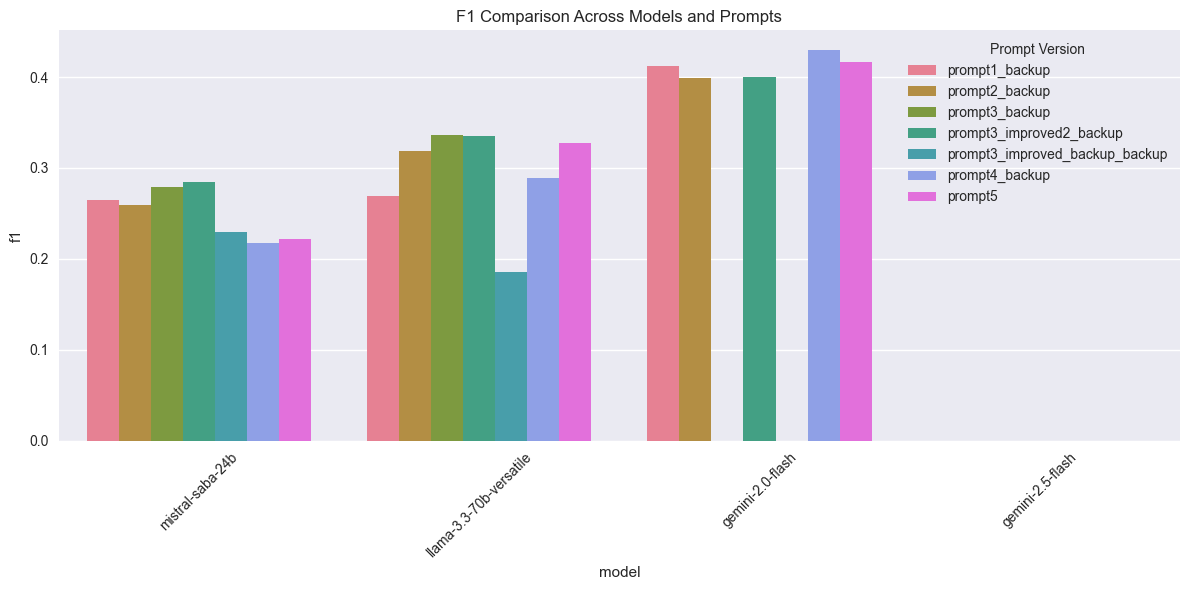

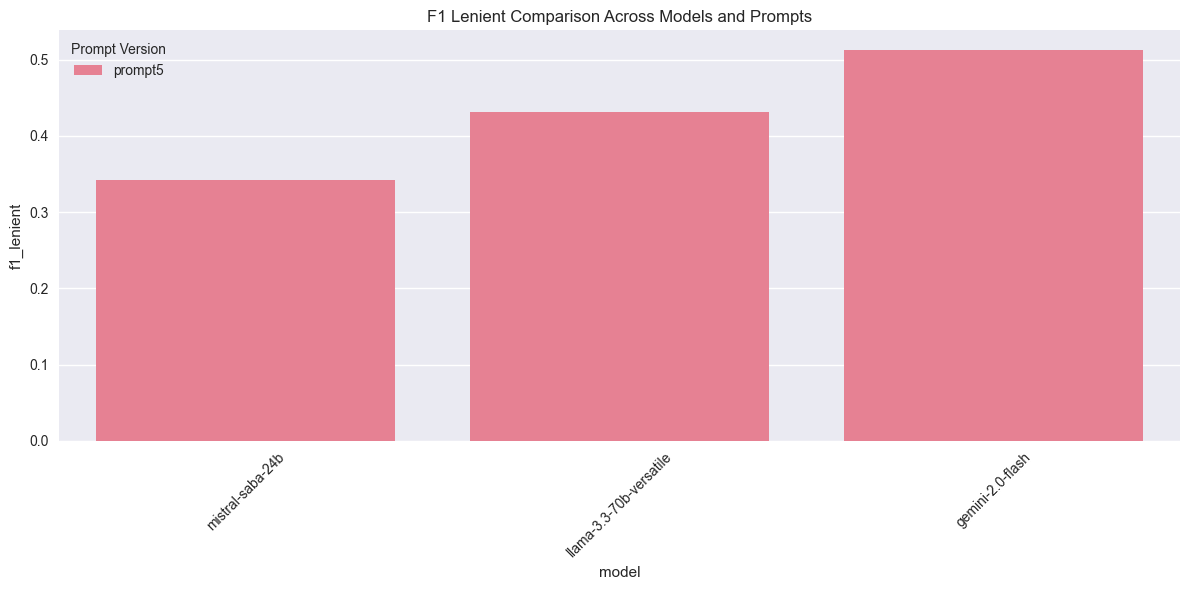

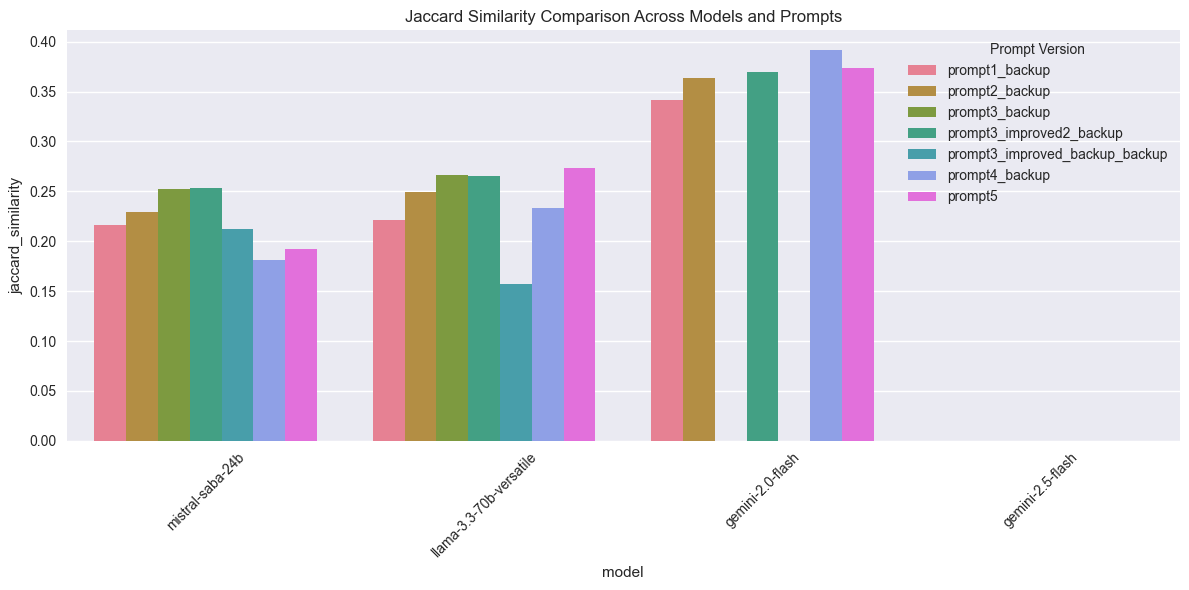

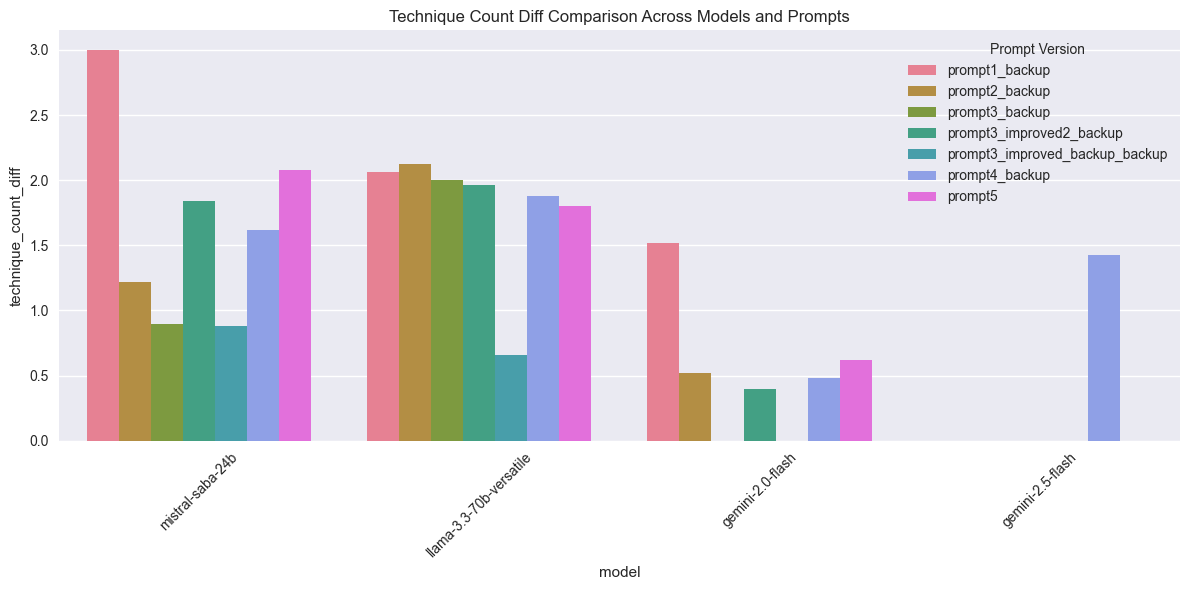

In [15]:
# Only rename if the column hasn't been renamed already
if 'Unnamed: 0' in combined_df.columns:
    combined_df = combined_df.rename(columns={'Unnamed: 0': 'model'})

def plot_metric_comparison(metric, title):
    # Filter out rows with NaN values for the specific metric
    plot_data = combined_df.dropna(subset=[metric])

    # Uncomment the following lines to filter for only Llama model:
    # plot_data = combined_df[combined_df['model'].str.contains('llama', case=False, na=False)].dropna(subset=[metric])

    if plot_data.empty:
        print(f"No data available for metric: {metric}")
        # For Llama-only version, use: print(f"No data available for metric: {metric} (Llama model only)")
        return

    plt.figure(figsize=(12, 6))
    sns.barplot(data=plot_data, x="model", y=metric, hue="prompt_version")
    # For Llama-only version, use: sns.barplot(data=plot_data, x="prompt_version", y=metric)
    plt.title(f"{title} Comparison Across Models and Prompts")
    # For Llama-only version, use: plt.title(f"{title} Comparison for Llama Model Across Prompts")
    plt.xticks(rotation=45)
    plt.legend(title="Prompt Version")
    # For Llama-only version, remove the legend line and use: plt.ylabel(metric.replace('_', ' ').title())
    plt.tight_layout()
    plt.show()


for metric in ["f1", "f1_lenient", "jaccard_similarity", "technique_count_diff"]:
    plot_metric_comparison(metric, metric.replace('_', ' ').title())

## Exact match - Partial match

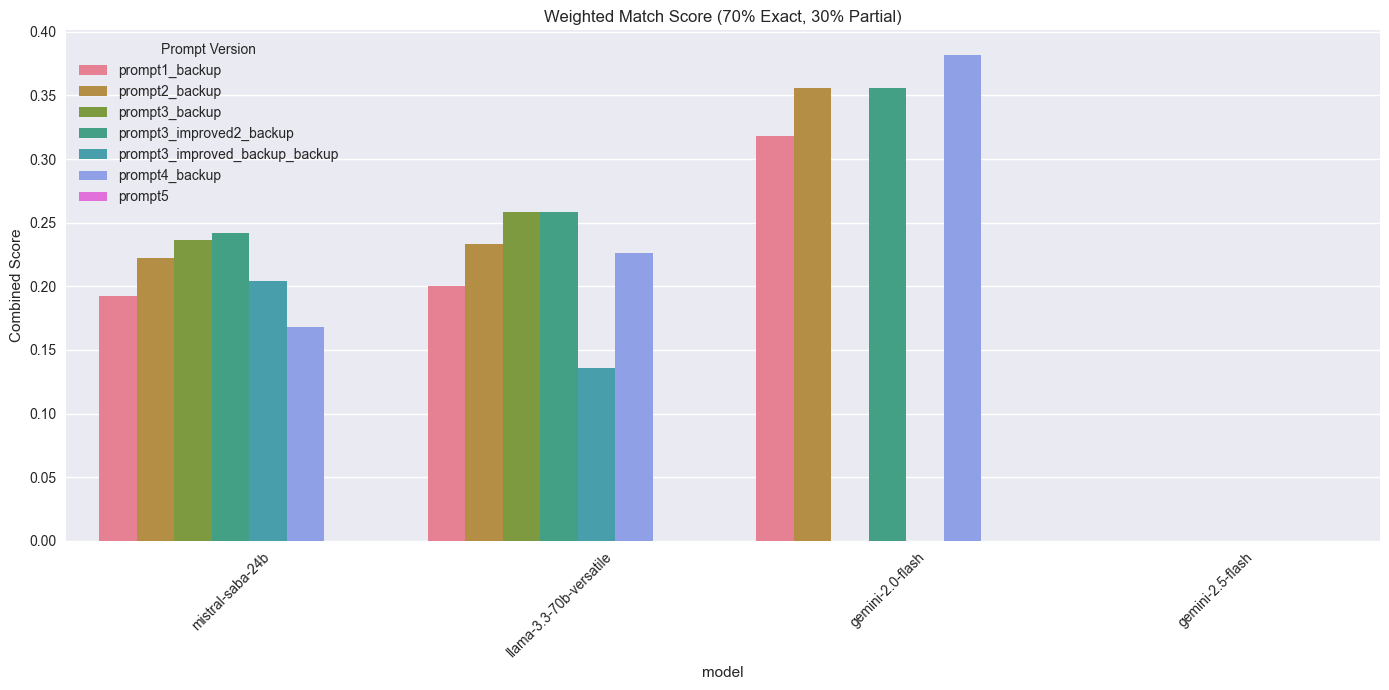

In [16]:
# 2. Weighted Combined Score (70% exact, 30% partial)
plt.figure(figsize=(14, 7))
combined_df["weighted_score"] = (
    0.7 * combined_df["exact_match"] + 0.3 * combined_df["partial_match"]
)

sns.barplot(data=combined_df, x="model", y="weighted_score", hue="prompt_version")
plt.title("Weighted Match Score (70% Exact, 30% Partial)")
plt.xticks(rotation=45)
plt.ylabel("Combined Score")
plt.legend(title="Prompt Version", loc='upper left')
plt.tight_layout()
plt.show()

## Technique Coverage Comparison

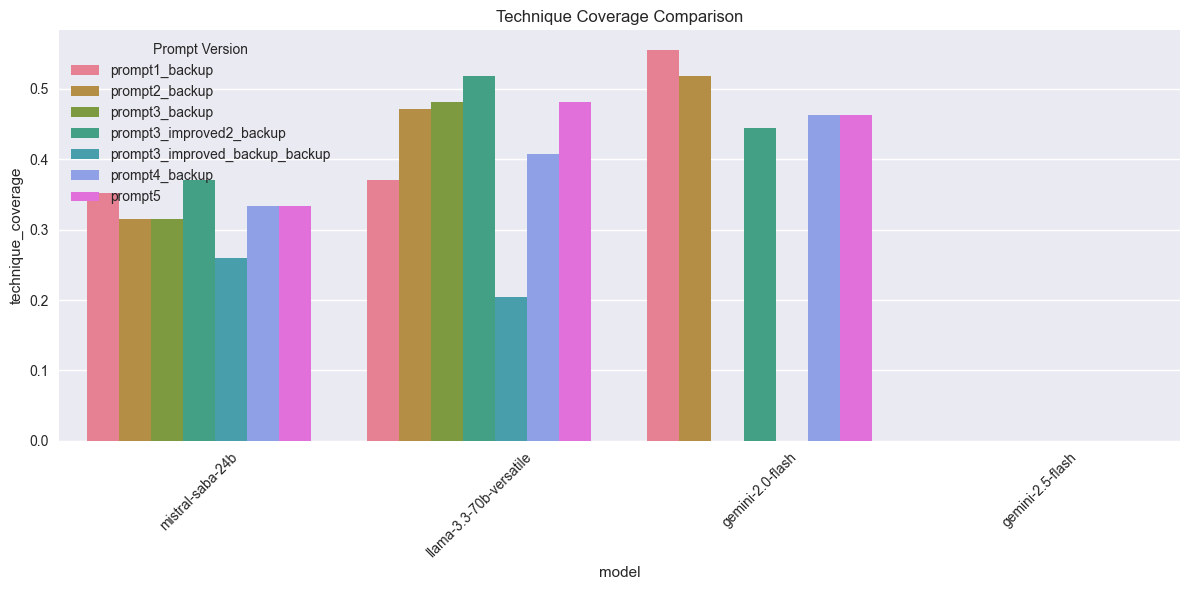

In [17]:
plt.figure(figsize=(12, 6))
sns.barplot(data=combined_df, x="model", y="technique_coverage", hue="prompt_version")
plt.title("Technique Coverage Comparison")
plt.xticks(rotation=45)
plt.legend(title="Prompt Version", loc='upper left')
plt.tight_layout()
plt.show()

## Worst Performing Techniques

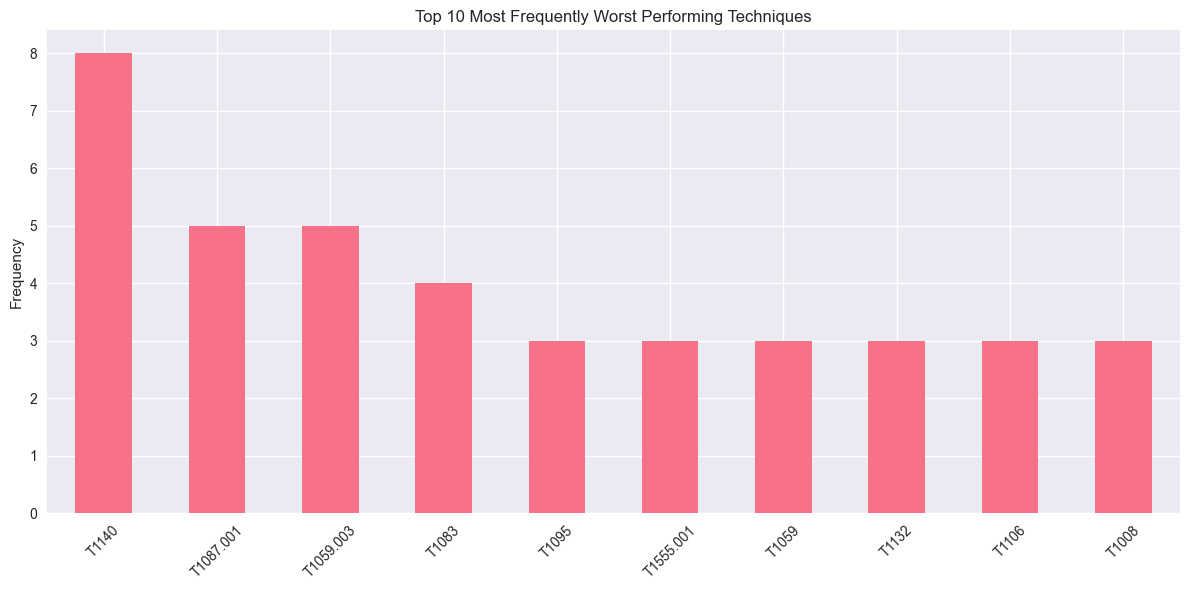

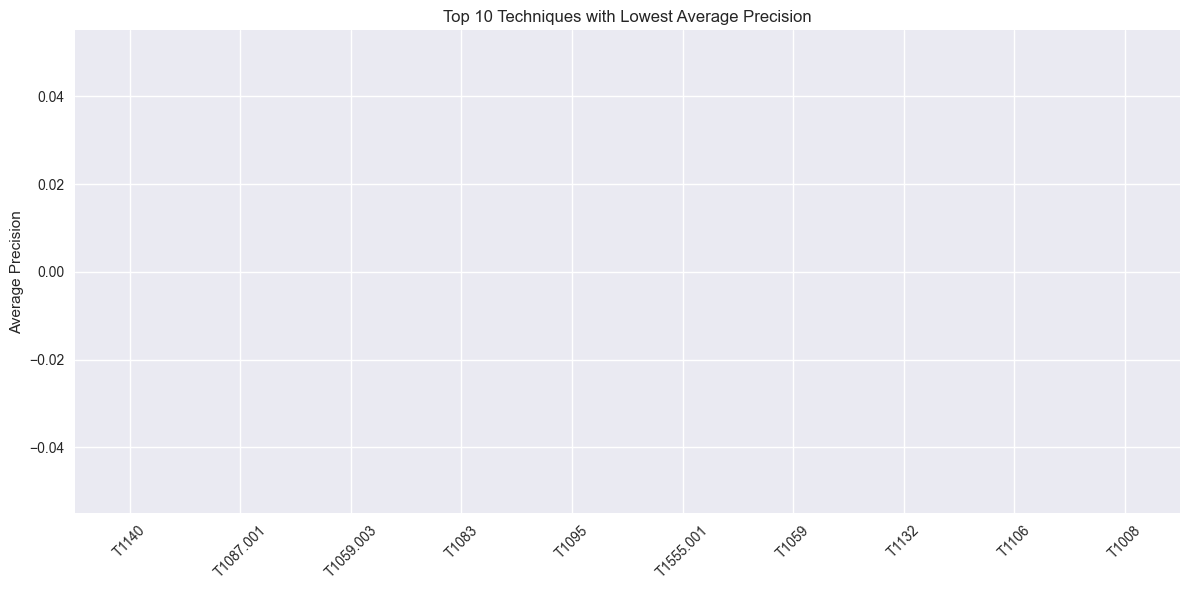

In [18]:
def analyze_worst_techniques():
    technique_stats = {}

    for _, row in combined_df.iterrows():
        try:
            worst_techs = ast.literal_eval(row["worst_performing_techniques"])
            for tech, stats in worst_techs:
                if tech not in technique_stats:
                    technique_stats[tech] = {"count": 0, "precision": [], "recall": []}
                technique_stats[tech]["count"] += 1
                technique_stats[tech]["precision"].append(stats["precision"])
                technique_stats[tech]["recall"].append(stats["recall"])
        except:
            continue

    if not technique_stats:
        print("No worst performing techniques data available")
        return

    # Create dataframe for visualization
    tech_df = pd.DataFrame.from_dict(
        {
            tech: {
                "count": stats["count"],
                "avg_precision": np.mean(stats["precision"]),
                "avg_recall": np.mean(stats["recall"]),
            }
            for tech, stats in technique_stats.items()
        },
        orient="index",
    )

    tech_df = tech_df.sort_values("count", ascending=False)

    # Plot most frequently worst performing techniques
    plt.figure(figsize=(12, 6))
    tech_df.head(10)["count"].plot(kind="bar")
    plt.title("Top 10 Most Frequently Worst Performing Techniques")
    plt.ylabel("Frequency")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    # Plot worst average precision techniques
    plt.figure(figsize=(12, 6))
    tech_df.sort_values("avg_precision").head(10)["avg_precision"].plot(kind="bar")
    plt.title("Top 10 Techniques with Lowest Average Precision")
    plt.ylabel("Average Precision")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


analyze_worst_techniques()